# 02 — Additional R3 experiments, cross-validation, CNN ablation and checks
**HAM10000 skin-lesion classification · F20DL Group 1**

Run after `01_data_split_classical_ml_and_cnns.ipynb`, which creates the checkpoints this notebook verifies.

| Part | Content | Report |
|---|---|---|
| 1 | Load data with the frozen split | — |
| 2 | Gaussian Naive Bayes and its smoothing sweep | Appendix C.2 |
| 3 | Decision-tree grid (40 settings) | Table 2, Appendix C.3 |
| 4 | Five-model validation comparison | Table 3 |
| 5 | Five-fold lesion-grouped cross-validation (first and corrected run) | §3.2, Table 3, Appendix C.5 |
| 6 | K-Means sweep over k = 2–10 | Appendix D.3 |
| 7 | Checkpoint and training-history verification | — |
| 8 | Small-CNN class-weight ablation | §4.2, Table 4, Appendix E.2 |
| 9 | Re-evaluation of the extended ResNet18 checkpoint | Appendix E.4 |
| 10 | Combined results tables and file inventory | Appendix E.5 |

Results are saved to `MyDrive/DMML_R3_Experiments/` (copied into `results/r3_experiments/` in this repository).

> **About the outputs in this notebook.** This is a cleaned, ordered version of the original Colab notebook
> `notebooks/original/HAM10000_R3_Outstanding_Experiments.ipynb`. Cells that only recovered from Colab disconnections, repeated earlier steps or failed are left out,
> and the remaining cells are arranged in the order the project was carried out. The outputs shown are the
> **outputs from the original Colab runs**, copied with their cells; the notebook was not re-executed as one session.
> The unedited original, including every error and recovery cell, is kept in `notebooks/original/`.
> Code is unchanged except where a cell is marked **(changed for this cleaned version)**.

### Before running
Run in Google Colab with a **T4 GPU** runtime. The notebooks expect this Google Drive folder:

```
MyDrive/DMML Project/
├── data/
│   ├── HAM10000_metadata.csv      (copy from this repository's data/ folder)
│   └── HAM10000_splits.csv        (copy from this repository's data/ folder)
└── HAM10000 Images/
    ├── HAM10000_images_part_1.zip (from the HAM10000 dataset on Harvard Dataverse)
    └── HAM10000_images_part_2.zip
```
Results and checkpoints are written back into the same Drive folder.

## Part 1 — Load data with the frozen split

In [ ]:

# (changed for this cleaned version) originally both CSVs were uploaded with files.upload();
# they are now read from the project folder in Google Drive.
import pandas as pd
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")
DATA = Path("/content/drive/MyDrive/DMML Project") / "data"

# Load dataset and existing split assignments
metadata = pd.read_csv(DATA / "HAM10000_metadata.csv")
splits = pd.read_csv(DATA / "HAM10000_splits.csv")

# Add the original train/validation/test assignments
df = metadata.merge(
    splits[["image_id", "split"]],
    on="image_id",
    how="left",
    validate="one_to_one"
)

# Verify data integrity
assert len(df) == 10015
assert df["split"].notna().all()
assert df["image_id"].is_unique

print("Dataset loaded successfully!")
print("\nTotal images:", len(df))
print("\nSplit distribution:")
print(df["split"].value_counts())

print("\nDiagnosis categories:")
print(df["dx"].value_counts())


## Part 2 — Gaussian Naive Bayes

In [2]:

import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

# Select metadata features
features = ["age", "sex", "localization"]

train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "val"].copy()

X_train = train_df[features]
y_train = train_df["dx"]

X_val = val_df[features]
y_val = val_df["dx"]

# Numeric preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="unknown"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, ["age"]),
    ("categorical", categorical_transformer, ["sex", "localization"])
])

# Build Naive Bayes pipeline
nb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GaussianNB())
])

# Train using training data only
nb_pipeline.fit(X_train, y_train)

# Predict on validation data
y_pred = nb_pipeline.predict(X_val)

# Calculate metrics
accuracy = accuracy_score(y_val, y_pred)
balanced_acc = balanced_accuracy_score(y_val, y_pred)
macro_f1 = f1_score(y_val, y_pred, average="macro")

print("GAUSSIAN NAIVE BAYES RESULTS")
print("----------------------------")
print(f"Accuracy: {accuracy:.4f}")
print(f"Balanced Accuracy: {balanced_acc:.4f}")
print(f"Macro F1: {macro_f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_val, y_pred, zero_division=0))



GAUSSIAN NAIVE BAYES RESULTS
----------------------------
Accuracy: 0.0239
Balanced Accuracy: 0.2241
Macro F1: 0.0368

Classification Report:
              precision    recall  f1-score   support

       akiec       0.10      0.34      0.16        35
         bcc       0.00      0.00      0.00       113
         bkl       0.11      0.02      0.03       162
          df       0.01      0.86      0.03        14
         mel       0.00      0.00      0.00       141
          nv       0.00      0.00      0.00       939
        vasc       0.02      0.35      0.04        20

    accuracy                           0.02      1424
   macro avg       0.04      0.22      0.04      1424
weighted avg       0.02      0.02      0.01      1424



In [3]:

from sklearn.base import clone

# Different smoothing values to investigate
smoothing_values = [
    1e-9, 1e-7, 1e-5, 1e-3,
    0.01, 0.1, 1.0, 10.0
]

results = []
best_score = -1
best_model = None

for smoothing in smoothing_values:

    model = clone(nb_pipeline)
    model.set_params(model__var_smoothing=smoothing)

    model.fit(X_train, y_train)
    predictions = model.predict(X_val)

    acc = accuracy_score(y_val, predictions)
    bal_acc = balanced_accuracy_score(y_val, predictions)
    f1 = f1_score(y_val, predictions, average="macro")

    results.append({
        "var_smoothing": smoothing,
        "Accuracy": acc,
        "Balanced Accuracy": bal_acc,
        "Macro F1": f1
    })

    if f1 > best_score:
        best_score = f1
        best_model = model

results_df = pd.DataFrame(results)

print("GAUSSIAN NAIVE BAYES TUNING RESULTS")
display(results_df.round(4))

print("\nBest validation Macro F1:", round(best_score, 4))
print(
    "Best smoothing:",
    best_model.named_steps["model"].var_smoothing
)


GAUSSIAN NAIVE BAYES TUNING RESULTS


,var_smoothing,Accuracy,Balanced Accuracy,Macro F1
0,0.000,0.0239,0.2241,0.0368
1,0.000,0.0267,0.2343,0.0381
2,0.000,0.0428,0.2425,0.0527
3,0.001,0.1587,0.3169,0.1122
4,0.010,0.4150,0.3153,0.1718
5,0.100,0.6966,0.2119,0.2115
6,1.000,0.6594,0.1429,0.1135
7,10.000,0.6594,0.1429,0.1135



Best validation Macro F1: 0.2115
Best smoothing: 0.1


TUNED NAIVE BAYES CLASSIFICATION REPORT
--------------------------------------
              precision    recall  f1-score   support

       akiec       0.00      0.00      0.00        35
         bcc       0.16      0.04      0.06       113
         bkl       0.48      0.38      0.42       162
          df       0.00      0.00      0.00        14
         mel       0.42      0.10      0.16       141
          nv       0.74      0.97      0.84       939
        vasc       0.00      0.00      0.00        20

    accuracy                           0.70      1424
   macro avg       0.26      0.21      0.21      1424
weighted avg       0.60      0.70      0.62      1424



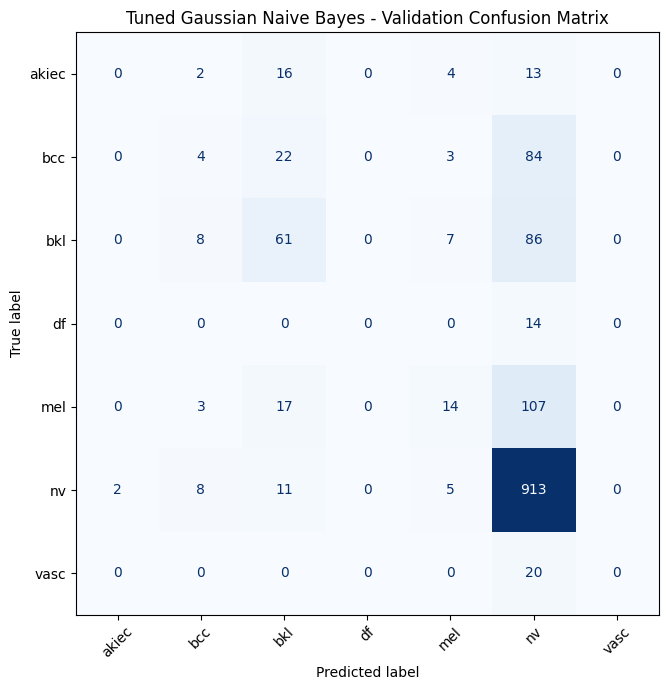


Results saved locally in: /content/naive_bayes_results


In [4]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from pathlib import Path

# Use the best model selected during tuning
y_pred_best = best_model.predict(X_val)

classes = sorted(y_val.unique())

print("TUNED NAIVE BAYES CLASSIFICATION REPORT")
print("--------------------------------------")

print(classification_report(
    y_val,
    y_pred_best,
    labels=classes,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    y_val,
    y_pred_best,
    labels=classes
)

fig, ax = plt.subplots(figsize=(9, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Tuned Gaussian Naive Bayes - Validation Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Save local results
output_dir = Path("/content/naive_bayes_results")
output_dir.mkdir(exist_ok=True)

results_df.to_csv(
    output_dir / "naive_bayes_tuning.csv",
    index=False
)

report_df = pd.DataFrame(
    classification_report(
        y_val,
        y_pred_best,
        labels=classes,
        output_dict=True,
        zero_division=0
    )
).transpose()

report_df.to_csv(
    output_dir / "naive_bayes_classification_report.csv"
)

fig.savefig(
    output_dir / "naive_bayes_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

print("\nResults saved locally in:", output_dir)


In [5]:

from google.colab import drive
from pathlib import Path
import shutil
import joblib
import json

# Connect Google Drive
drive.mount("/content/drive")

# Create a permanent folder in My Drive
save_dir = Path(
    "/content/drive/MyDrive/DMML_R3_Experiments/Naive_Bayes"
)
save_dir.mkdir(parents=True, exist_ok=True)

# Copy existing results
source_dir = Path("/content/naive_bayes_results")

for file in source_dir.iterdir():
    if file.is_file():
        shutil.copy2(file, save_dir / file.name)

# Save the trained model and preprocessing pipeline
joblib.dump(
    best_model,
    save_dir / "best_naive_bayes.joblib"
)

# Save the selected model's metrics
metrics = {
    "model": "Gaussian Naive Bayes",
    "features": ["age", "sex", "localization"],
    "validation_accuracy": float(
        accuracy_score(y_val, y_pred_best)
    ),
    "validation_balanced_accuracy": float(
        balanced_accuracy_score(y_val, y_pred_best)
    ),
    "validation_macro_f1": float(
        f1_score(y_val, y_pred_best, average="macro")
    ),
    "best_var_smoothing": float(
        best_model.named_steps["model"].var_smoothing
    ),
    "evaluation_split": "validation"
}

with open(save_dir / "model_metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

print("FILES SAVED SUCCESSFULLY!\n")

for file in sorted(save_dir.iterdir()):
    print(file.name)

print("\nSaved to:", save_dir)


Mounted at /content/drive
FILES SAVED SUCCESSFULLY!

best_naive_bayes.joblib
model_metrics.json
naive_bayes_classification_report.csv
naive_bayes_confusion_matrix.png
naive_bayes_tuning.csv

Saved to: /content/drive/MyDrive/DMML_R3_Experiments/Naive_Bayes


## Part 3 — Decision tree grid search

In [6]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import ParameterGrid
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)
import pandas as pd

# Decision Tree preprocessing and training pipeline
dt_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", DecisionTreeClassifier(random_state=42))
])

# Hyperparameters to investigate
param_grid = {
    "model__max_depth": [3, 5, 10, 15, None],
    "model__min_samples_leaf": [1, 5, 10, 20],
    "model__class_weight": [None, "balanced"]
}

dt_results = []
best_dt_score = -1
best_dt_model = None

for params in ParameterGrid(param_grid):

    model = clone(dt_pipeline)
    model.set_params(**params)

    # Train on training partition only
    model.fit(X_train, y_train)

    # Predict validation labels
    predictions = model.predict(X_val)

    accuracy = accuracy_score(y_val, predictions)
    balanced_acc = balanced_accuracy_score(y_val, predictions)
    macro_f1 = f1_score(
        y_val, predictions, average="macro"
    )

    dt_results.append({
        "max_depth": str(params["model__max_depth"]),
        "min_samples_leaf": params["model__min_samples_leaf"],
        "class_weight": str(params["model__class_weight"]),
        "Accuracy": accuracy,
        "Balanced Accuracy": balanced_acc,
        "Macro F1": macro_f1
    })

    if macro_f1 > best_dt_score:
        best_dt_score = macro_f1
        best_dt_model = model

# Display results ranked by validation Macro F1
dt_results_df = pd.DataFrame(dt_results)

dt_results_df = dt_results_df.sort_values(
    "Macro F1",
    ascending=False
).reset_index(drop=True)

print("TOP 10 DECISION TREE CONFIGURATIONS")
display(dt_results_df.head(10).round(4))

print("\nBEST VALIDATION MACRO F1:", round(best_dt_score, 4))
print("\nBEST PARAMETERS:")
print(best_dt_model.named_steps["model"].get_params())


TOP 10 DECISION TREE CONFIGURATIONS


,max_depth,min_samples_leaf,class_weight,Accuracy,Balanced Accuracy,Macro F1
0,None,5,None,0.6728,0.2155,0.2191
1,10,5,None,0.6784,0.2135,0.2167
2,10,1,balanced,0.3862,0.3059,0.2148
3,10,5,balanced,0.3848,0.3056,0.2144
4,None,10,balanced,0.3581,0.2993,0.2141
5,None,1,balanced,0.3715,0.2889,0.2124
6,10,10,None,0.6770,0.2092,0.2123
7,15,1,balanced,0.3673,0.2957,0.2118
8,10,20,balanced,0.3603,0.3108,0.2116
9,10,10,balanced,0.3792,0.3033,0.2114



BEST VALIDATION MACRO F1: 0.2191

BEST PARAMETERS:
{'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 5, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 42, 'splitter': 'best'}


TUNED DECISION TREE CLASSIFICATION REPORT
-----------------------------------------
              precision    recall  f1-score   support

       akiec       0.14      0.09      0.11        35
         bcc       0.23      0.06      0.10       113
         bkl       0.41      0.31      0.36       162
          df       0.00      0.00      0.00        14
         mel       0.18      0.11      0.13       141
          nv       0.76      0.94      0.84       939
        vasc       0.00      0.00      0.00        20

    accuracy                           0.67      1424
   macro avg       0.25      0.22      0.22      1424
weighted avg       0.59      0.67      0.62      1424



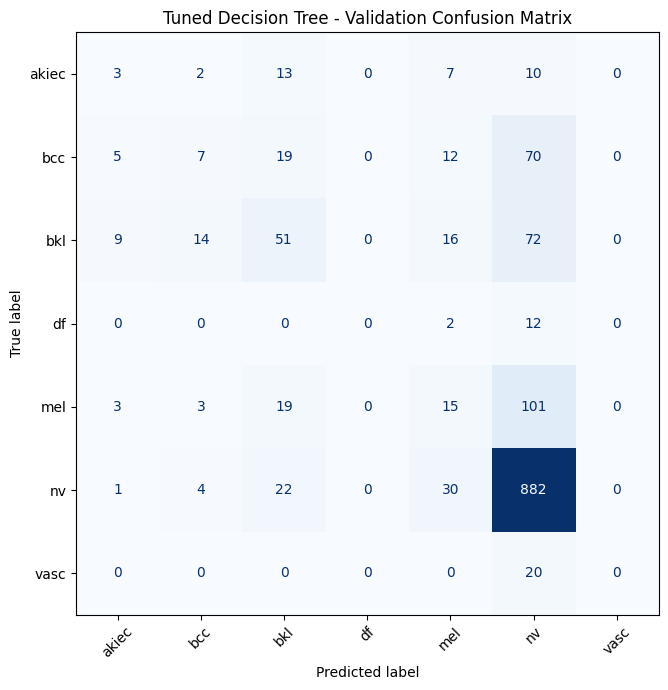


FILES SAVED SUCCESSFULLY!
best_decision_tree.joblib
decision_tree_classification_report.csv
decision_tree_confusion_matrix.png
decision_tree_tuning.csv
model_metrics.json

Saved to: /content/drive/MyDrive/DMML_R3_Experiments/Decision_Tree


In [7]:

import matplotlib.pyplot as plt
import joblib
import json

from pathlib import Path
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

# Predict using best tuned Decision Tree
dt_pred = best_dt_model.predict(X_val)

classes = sorted(y_val.unique())

# Display classification report
print("TUNED DECISION TREE CLASSIFICATION REPORT")
print("-----------------------------------------")

print(classification_report(
    y_val,
    dt_pred,
    labels=classes,
    zero_division=0
))

# Generate confusion matrix
cm = confusion_matrix(
    y_val,
    dt_pred,
    labels=classes
)

fig, ax = plt.subplots(figsize=(9, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Tuned Decision Tree - Validation Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()

# Save directly to Google Drive
save_dir = Path(
    "/content/drive/MyDrive/DMML_R3_Experiments/Decision_Tree"
)

save_dir.mkdir(parents=True, exist_ok=True)

# Save model
joblib.dump(
    best_dt_model,
    save_dir / "best_decision_tree.joblib"
)

# Save tuning results
dt_results_df.to_csv(
    save_dir / "decision_tree_tuning.csv",
    index=False
)

# Save classification report
report_df = pd.DataFrame(
    classification_report(
        y_val,
        dt_pred,
        labels=classes,
        output_dict=True,
        zero_division=0
    )
).transpose()

report_df.to_csv(
    save_dir / "decision_tree_classification_report.csv"
)

# Save confusion matrix
fig.savefig(
    save_dir / "decision_tree_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save metrics and selected settings
tree = best_dt_model.named_steps["model"]

metrics = {
    "model": "Decision Tree",
    "evaluation_split": "validation",
    "accuracy": float(accuracy_score(y_val, dt_pred)),
    "balanced_accuracy": float(
        balanced_accuracy_score(y_val, dt_pred)
    ),
    "macro_f1": float(
        f1_score(y_val, dt_pred, average="macro")
    ),
    "max_depth": tree.max_depth,
    "min_samples_leaf": tree.min_samples_leaf,
    "class_weight": tree.class_weight
}

with open(save_dir / "model_metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

print("\nFILES SAVED SUCCESSFULLY!")

for file in sorted(save_dir.iterdir()):
    print(file.name)

print("\nSaved to:", save_dir)


In [8]:

from pathlib import Path

save_dir = Path(
    "/content/drive/MyDrive/DMML_R3_Experiments/Decision_Tree"
)

expected_files = [
    "best_decision_tree.joblib",
    "decision_tree_tuning.csv",
    "decision_tree_classification_report.csv",
    "decision_tree_confusion_matrix.png",
    "model_metrics.json"
]

print("DECISION TREE SAVE VERIFICATION\n")

for filename in expected_files:
    filepath = save_dir / filename

    if filepath.exists() and filepath.stat().st_size > 0:
        print("PASS:", filename)
    else:
        print("MISSING:", filename)

print("\nFolder:", save_dir)


DECISION TREE SAVE VERIFICATION

PASS: best_decision_tree.joblib
PASS: decision_tree_tuning.csv
PASS: decision_tree_classification_report.csv
PASS: decision_tree_confusion_matrix.png
PASS: model_metrics.json

Folder: /content/drive/MyDrive/DMML_R3_Experiments/Decision_Tree


## Part 4 — Five-model validation comparison
The Logistic Regression, Random Forest and kNN rows are the tuned values computed in notebook 01 (Part 6), entered here as numbers.

In [9]:

import pandas as pd

# Recorded results from the original project
original_results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": 0.4052,
        "Balanced Accuracy": 0.3398,
        "Macro F1": 0.2021
    },
    {
        "Model": "Random Forest",
        "Accuracy": 0.4171,
        "Balanced Accuracy": 0.3079,
        "Macro F1": 0.2281
    },
    {
        "Model": "kNN",
        "Accuracy": 0.6629,
        "Balanced Accuracy": 0.2311,
        "Macro F1": 0.2352
    }
])

print("ORIGINAL TUNED CLASSICAL ML RESULTS")
display(original_results)



ORIGINAL TUNED CLASSICAL ML RESULTS


,Model,Accuracy,Balanced Accuracy,Macro F1
0,Logistic Regression,0.4052,0.3398,0.2021
1,Random Forest,0.4171,0.3079,0.2281
2,kNN,0.6629,0.2311,0.2352


FIVE-MODEL VALIDATION COMPARISON


,Model,Accuracy,Balanced Accuracy,Macro F1
0,kNN,0.6629,0.2311,0.2352
1,Random Forest,0.4171,0.3079,0.2281
2,Decision Tree (Tuned),0.6728,0.2155,0.2191
3,Naive Bayes (Tuned),0.6966,0.2119,0.2115
4,Logistic Regression,0.4052,0.3398,0.2021


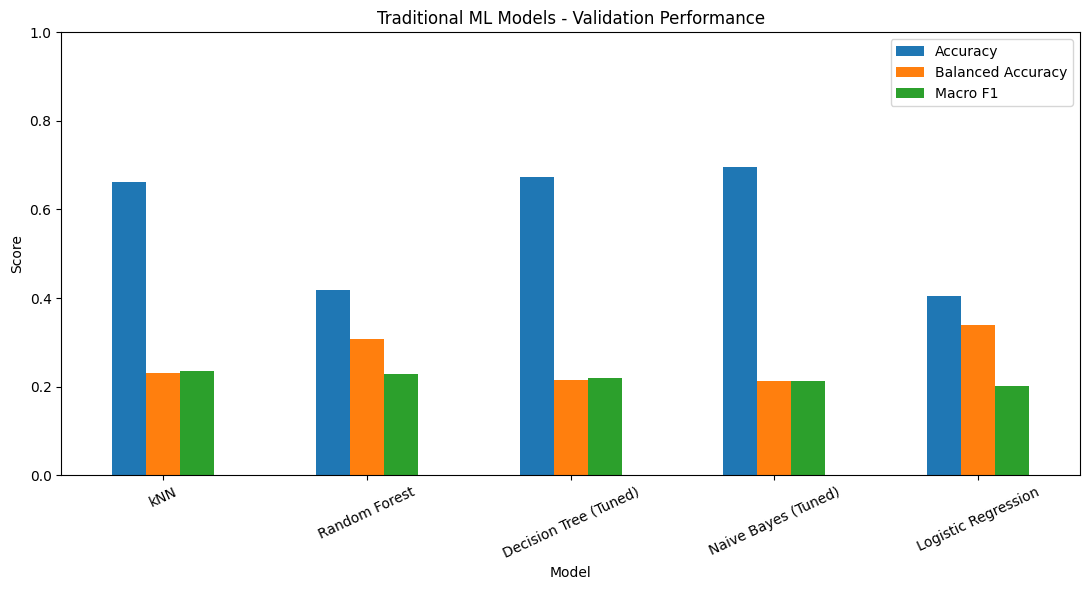


Comparison saved successfully!
Location: /content/drive/MyDrive/DMML_R3_Experiments/Comparison


In [10]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Results from the original project
comparison = original_results.copy()

# Add our newly trained models
new_results = pd.DataFrame([
    {
        "Model": "Decision Tree (Tuned)",
        "Accuracy": accuracy_score(y_val, dt_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_val, dt_pred),
        "Macro F1": f1_score(y_val, dt_pred, average="macro")
    },
    {
        "Model": "Naive Bayes (Tuned)",
        "Accuracy": accuracy_score(y_val, y_pred_best),
        "Balanced Accuracy": balanced_accuracy_score(y_val, y_pred_best),
        "Macro F1": f1_score(y_val, y_pred_best, average="macro")
    }
])

comparison = pd.concat(
    [comparison, new_results],
    ignore_index=True
)

# Rank models by Macro F1
comparison = comparison.sort_values(
    "Macro F1",
    ascending=False
).reset_index(drop=True)

print("FIVE-MODEL VALIDATION COMPARISON")
display(comparison.round(4))

# Create comparison chart
ax = comparison.set_index("Model")[
    ["Accuracy", "Balanced Accuracy", "Macro F1"]
].plot(kind="bar", figsize=(11, 6))

ax.set_title("Traditional ML Models - Validation Performance")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=25)

plt.legend()
plt.tight_layout()

# Save results permanently
save_dir = Path(
    "/content/drive/MyDrive/DMML_R3_Experiments/Comparison"
)
save_dir.mkdir(parents=True, exist_ok=True)

comparison.to_csv(
    save_dir / "five_model_comparison.csv",
    index=False
)

plt.savefig(
    save_dir / "five_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nComparison saved successfully!")
print("Location:", save_dir)


## Part 5 — Five-fold lesion-grouped cross-validation
The first run used settings that did not match the tuned models (kNN without distance weighting; Random Forest with 100 trees). It is kept for transparency; the corrected run that follows is the one reported.

In [11]:

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

# Use train + validation only
development_df = df[df["split"].isin(["train", "val"])].copy()

X_dev = development_df[["age", "sex", "localization"]]
y_dev = development_df["dx"]
groups = development_df["lesion_id"]

print("Development images:", len(development_df))
print("Unique lesions:", groups.nunique())
print("Held-out test images excluded:",
      (df["split"] == "test").sum())

# Five-fold lesion-grouped cross-validation
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Selected model configurations
models = {
    "Logistic Regression": LogisticRegression(
        C=0.001,
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "kNN": KNeighborsClassifier(
        n_neighbors=11
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=None,
        min_samples_leaf=5,
        class_weight=None,
        random_state=42
    ),

    "Naive Bayes": GaussianNB(
        var_smoothing=0.1
    )
}

scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "macro_f1": "f1_macro"
}

cv_results = []

for name, classifier in models.items():

    print("Running:", name)

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", classifier)
    ])

    scores = cross_validate(
        pipeline,
        X_dev,
        y_dev,
        groups=groups,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        error_score="raise"
    )

    cv_results.append({
        "Model": name,
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Mean Balanced Accuracy": scores["test_balanced_accuracy"].mean(),
        "Mean Macro F1": scores["test_macro_f1"].mean(),
        "Macro F1 SD": scores["test_macro_f1"].std()
    })

cv_results_df = pd.DataFrame(cv_results)

cv_results_df = cv_results_df.sort_values(
    "Mean Macro F1",
    ascending=False
).reset_index(drop=True)

print("\nFIVE-FOLD GROUPED CROSS-VALIDATION RESULTS")
display(cv_results_df.round(4))


Development images: 8593
Unique lesions: 6403
Held-out test images excluded: 1422
Running: Logistic Regression
Running: Random Forest
Running: kNN
Running: Decision Tree
Running: Naive Bayes

FIVE-FOLD GROUPED CROSS-VALIDATION RESULTS


,Model,Mean Accuracy,Mean Balanced Accuracy,Mean Macro F1,Macro F1 SD
0,Random Forest,0.4118,0.3200,0.2206,0.0107
1,Decision Tree,0.6829,0.2134,0.2132,0.0101
2,Naive Bayes,0.6878,0.2105,0.2117,0.0169
3,Logistic Regression,0.4145,0.2986,0.1954,0.0121
4,kNN,0.4292,0.2338,0.1824,0.0046


In [12]:

print("CROSS-VALIDATION MODEL CONFIGURATIONS")
print("-------------------------------------")

for name, model in models.items():
    print(f"\n{name}")
    print(model.get_params())

print("\nPREPROCESSING CONFIGURATION")
print("---------------------------")
print(preprocessor)


CROSS-VALIDATION MODEL CONFIGURATIONS
-------------------------------------

Logistic Regression
{'C': 0.001, 'class_weight': 'balanced', 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 1000, 'multi_class': 'deprecated', 'n_jobs': None, 'penalty': 'l2', 'random_state': 42, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}

Random Forest
{'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 10, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 10, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}

kNN
{'algorithm': 'auto', 'leaf_size': 30, 'metric': 'minkowski', 'metric_params': None, 'n_jobs': None, 'n_neighbors': 11, 'p': 2, 'weights': 'uniform'}

Decision Tree
{'ccp_alpha

In [13]:

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

# Corrected model configurations
models = {
    "Logistic Regression": LogisticRegression(
        C=0.001,
        max_iter=3000,
        class_weight="balanced",
        random_state=123
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=10,
        class_weight="balanced_subsample",
        random_state=123,
        n_jobs=-1
    ),

    "kNN": KNeighborsClassifier(
        n_neighbors=11,
        weights="distance"
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=None,
        min_samples_leaf=5,
        class_weight=None,
        random_state=42
    ),

    "Naive Bayes": GaussianNB(
        var_smoothing=0.1
    )
}

print("Corrected model configurations loaded!")


Corrected model configurations loaded!


In [14]:

# Re-run cross-validation with corrected models

cv_results = []

for name, classifier in models.items():
    print("Running:", name)

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", clone(classifier))
    ])

    scores = cross_validate(
        pipeline,
        X_dev,
        y_dev,
        groups=groups,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        error_score="raise"
    )

    cv_results.append({
        "Model": name,
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Mean Balanced Accuracy": scores["test_balanced_accuracy"].mean(),
        "Mean Macro F1": scores["test_macro_f1"].mean(),
        "Macro F1 SD": scores["test_macro_f1"].std()
    })

cv_results_df = pd.DataFrame(cv_results)

cv_results_df = cv_results_df.sort_values(
    "Mean Macro F1",
    ascending=False
).reset_index(drop=True)

print("\nCORRECTED FIVE-FOLD CROSS-VALIDATION RESULTS")
display(cv_results_df.round(4))


Running: Logistic Regression
Running: Random Forest
Running: kNN
Running: Decision Tree
Running: Naive Bayes

CORRECTED FIVE-FOLD CROSS-VALIDATION RESULTS


,Model,Mean Accuracy,Mean Balanced Accuracy,Mean Macro F1,Macro F1 SD
0,Random Forest,0.4147,0.3210,0.2224,0.0051
1,Decision Tree,0.6829,0.2134,0.2132,0.0101
2,Naive Bayes,0.6878,0.2105,0.2117,0.0169
3,Logistic Regression,0.4145,0.2986,0.1954,0.0121
4,kNN,0.4253,0.2322,0.1849,0.0040


In [15]:

from pathlib import Path

save_dir = Path(
    "/content/drive/MyDrive/DMML_R3_Experiments/Cross_Validation"
)
save_dir.mkdir(parents=True, exist_ok=True)

cv_results_df.to_csv(
    save_dir / "five_fold_grouped_cv_results.csv",
    index=False
)

print("Cross-validation results saved successfully!")
print("Location:", save_dir)


Cross-validation results saved successfully!
Location: /content/drive/MyDrive/DMML_R3_Experiments/Cross_Validation


## Part 6 — Choosing the number of clusters (k = 2–10)

In [16]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.base import clone
import pandas as pd

# Use only training data
X_cluster = X_train.copy()

# Fit preprocessing on training data
cluster_preprocessor = clone(preprocessor)
X_cluster_processed = cluster_preprocessor.fit_transform(
    X_cluster
)

# Test different cluster counts
cluster_results = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_cluster_processed)

    # Silhouette score measures cluster separation
    score = silhouette_score(
        X_cluster_processed,
        labels,
        sample_size=min(3000, len(X_cluster_processed)),
        random_state=42
    )

    cluster_results.append({
        "Clusters": k,
        "Silhouette Score": score,
        "Inertia": kmeans.inertia_
    })

cluster_results_df = pd.DataFrame(cluster_results)

print("K-MEANS CLUSTER COUNT EXPERIMENT")
display(cluster_results_df.round(4))

best_row = cluster_results_df.loc[
    cluster_results_df["Silhouette Score"].idxmax()
]

print("\nBest cluster count:", int(best_row["Clusters"]))
print("Best silhouette score:", round(best_row["Silhouette Score"], 4))


K-MEANS CLUSTER COUNT EXPERIMENT


,Clusters,Silhouette Score,Inertia
0,2,0.2427,12071.0262
1,3,0.2427,9906.4346
2,4,0.2343,8672.0776
3,5,0.2292,7904.1962
4,6,0.2316,7421.8533
5,7,0.2089,7020.0082
6,8,0.2214,6678.6341
7,9,0.2345,6275.8584
8,10,0.2745,5914.8083



Best cluster count: 10
Best silhouette score: 0.2745


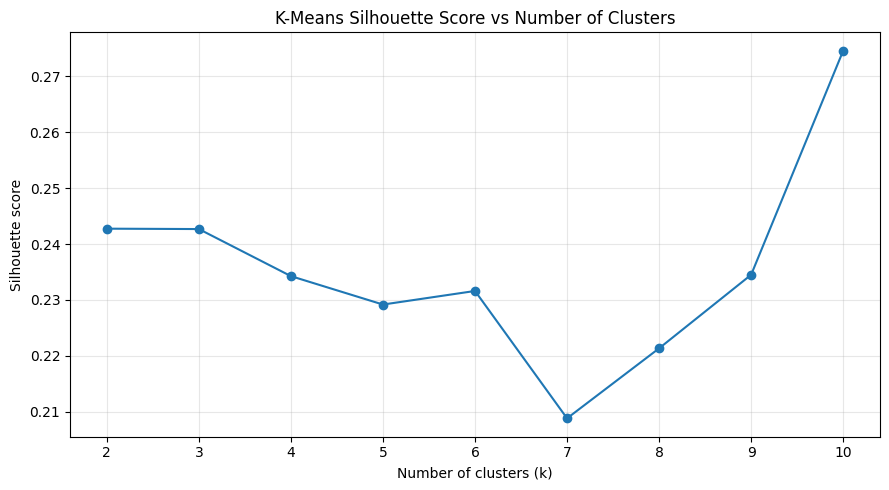

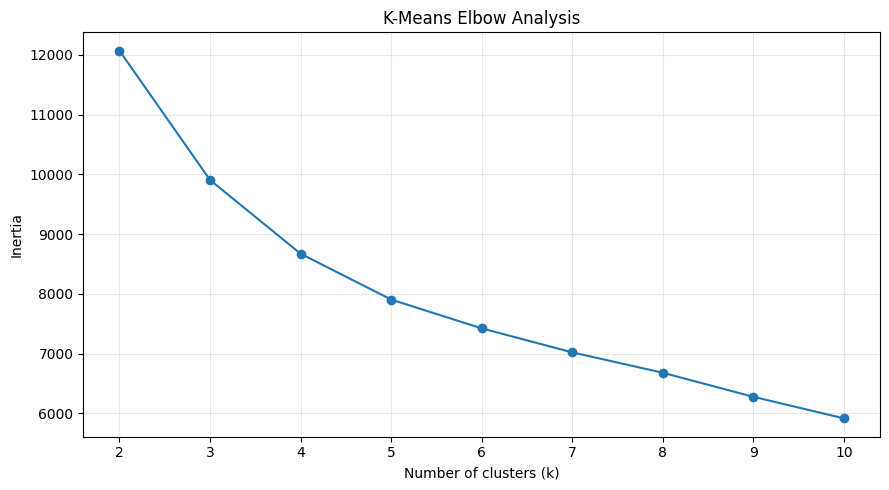

Clustering results saved successfully!
Location: /content/drive/MyDrive/DMML_R3_Experiments/Clustering


In [17]:

import matplotlib.pyplot as plt
from pathlib import Path

# Create permanent output folder
save_dir = Path(
    "/content/drive/MyDrive/DMML_R3_Experiments/Clustering"
)
save_dir.mkdir(parents=True, exist_ok=True)

# Save numerical results
cluster_results_df.to_csv(
    save_dir / "kmeans_cluster_count_results.csv",
    index=False
)

# Silhouette score graph
plt.figure(figsize=(9, 5))
plt.plot(
    cluster_results_df["Clusters"],
    cluster_results_df["Silhouette Score"],
    marker="o"
)

plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.title("K-Means Silhouette Score vs Number of Clusters")
plt.xticks(range(2, 11))
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    save_dir / "kmeans_silhouette_sweep.png",
    dpi=300
)
plt.show()

# Elbow graph
plt.figure(figsize=(9, 5))
plt.plot(
    cluster_results_df["Clusters"],
    cluster_results_df["Inertia"],
    marker="o"
)

plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Analysis")
plt.xticks(range(2, 11))
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    save_dir / "kmeans_elbow_plot.png",
    dpi=300
)
plt.show()

print("Clustering results saved successfully!")
print("Location:", save_dir)


In [18]:

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
import pandas as pd

# Training diagnosis labels are only used for evaluation
# They are NOT supplied to K-Means during fitting.
true_labels = train_df["dx"].to_numpy()

ari_results = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    predicted_clusters = model.fit_predict(
        X_cluster_processed
    )

    ari = adjusted_rand_score(
        true_labels,
        predicted_clusters
    )

    ari_results.append({
        "Clusters": k,
        "ARI": ari
    })

ari_results_df = pd.DataFrame(ari_results)

# Combine with existing silhouette results
cluster_full_results = cluster_results_df.merge(
    ari_results_df,
    on="Clusters",
    validate="one_to_one"
)

print("K-MEANS CLUSTER EVALUATION")
display(cluster_full_results.round(4))

# Save permanently
cluster_full_results.to_csv(
    save_dir / "kmeans_full_cluster_evaluation.csv",
    index=False
)

print("\nResults saved successfully!")


K-MEANS CLUSTER EVALUATION


,Clusters,Silhouette Score,Inertia,ARI
0,2,0.2427,12071.0262,0.1772
1,3,0.2427,9906.4346,0.0741
2,4,0.2343,8672.0776,0.0648
3,5,0.2292,7904.1962,0.0602
4,6,0.2316,7421.8533,0.0512
5,7,0.2089,7020.0082,0.0434
6,8,0.2214,6678.6341,0.0432
7,9,0.2345,6275.8584,0.0197
8,10,0.2745,5914.8083,0.0188



Results saved successfully!


## Part 7 — Feature-importance summary and checkpoint verification
The first cell shows the feature-importance values computed in notebook 01 (Part 7).

In [19]:

import pandas as pd

# Previously recorded feature importance results
feature_importance = pd.DataFrame({
    "Feature": ["age", "localization", "sex"],
    "Importance": [0.0594, 0.0559, 0.0028]
})

feature_selection = pd.DataFrame({
    "Experiment": [
        "All three features",
        "Without sex"
    ],
    "Macro F1": [
        0.2281,
        0.2147
    ]
})

print("FEATURE IMPORTANCE")
display(feature_importance)

print("\nFEATURE SELECTION COMPARISON")
display(feature_selection)


FEATURE IMPORTANCE


,Feature,Importance
0,age,0.0594
1,localization,0.0559
2,sex,0.0028



FEATURE SELECTION COMPARISON


,Experiment,Macro F1
0,All three features,0.2281
1,Without sex,0.2147


In [22]:

from pathlib import Path
import torch

project = Path("/content/drive/MyDrive/DMML Project")

checkpoints = {
    "Small CNN":
        project / "CNN Results" / "best_small_cnn.pth",

    "Frozen ResNet18":
        project / "CNN Results" / "ResNet18" / "best_resnet18.pth",

    "Fine-tuned ResNet18":
        project / "CNN Results" / "ResNet18" / "best_resnet18_finetuned.pth",

    "Improved ResNet18":
        project / "CNN Results" / "ResNet18" /
        "Improvement_Experiment" / "best_improved_resnet18.pth"
}

print("MODEL CHECKPOINT VERIFICATION\n")

for name, path in checkpoints.items():
    print(f"\n{name}")

    if not path.exists():
        print("NOT FOUND:", path)
        continue

    print(f"File found: {path.stat().st_size / 1024**2:.2f} MB")

    try:
        checkpoint = torch.load(
            path,
            map_location="cpu",
            weights_only=True
        )

        print("Checkpoint loaded successfully")
        print("Checkpoint type:", type(checkpoint).__name__)

        if isinstance(checkpoint, dict):
            print("First five keys:", list(checkpoint.keys())[:5])

    except Exception as e:
        print("Loading error:", str(e))


MODEL CHECKPOINT VERIFICATION


Small CNN
File found: 0.29 MB
Checkpoint loaded successfully
Checkpoint type: dict
First five keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'best_val_macro_f1', 'classes']

Frozen ResNet18
File found: 42.75 MB
Checkpoint loaded successfully
Checkpoint type: dict
First five keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'best_val_macro_f1', 'classes']

Fine-tuned ResNet18
File found: 42.73 MB
Checkpoint loaded successfully
Checkpoint type: dict
First five keys: ['epoch', 'model_state_dict', 'best_val_macro_f1', 'classes']

Improved ResNet18
File found: 42.73 MB
Checkpoint loaded successfully
Checkpoint type: dict
First five keys: ['model_state_dict', 'best_val_macro_f1', 'epoch', 'classes']


In [23]:

import torch
import pandas as pd

checkpoint_results = []

for name, path in checkpoints.items():

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    checkpoint_results.append({
        "Model": name,
        "Saved Epoch": checkpoint.get("epoch"),
        "Best Validation Macro F1": checkpoint.get(
            "best_val_macro_f1"
        ),
        "Number of Classes": len(
            checkpoint.get("classes", [])
        ),
        "Weights Available": (
            "model_state_dict" in checkpoint
        )
    })

checkpoint_df = pd.DataFrame(checkpoint_results)

print("SAVED NEURAL NETWORK CHECKPOINT INFORMATION")
display(checkpoint_df)


SAVED NEURAL NETWORK CHECKPOINT INFORMATION


,Model,Saved Epoch,Best Validation Macro F1,Number of Classes,Weights Available
0,Small CNN,10,0.358467,7,True
1,Frozen ResNet18,10,0.435367,7,True
2,Fine-tuned ResNet18,3,0.485709,7,True
3,Improved ResNet18,17,0.610301,7,True


In [24]:

import pandas as pd

history_paths = {
    "Small CNN":
        project / "CNN Results" /
        "small_cnn_training_history.csv",

    "Frozen ResNet18":
        project / "CNN Results" / "ResNet18" /
        "resnet18_training_history.csv",

    "Fine-tuned ResNet18":
        project / "CNN Results" / "ResNet18" /
        "resnet18_finetuning_history.csv",

    "Improved ResNet18":
        project / "CNN Results" / "ResNet18" /
        "Improvement_Experiment" /
        "improvement_history.csv"
}

print("TRAINING HISTORY VERIFICATION\n")

for name, path in history_paths.items():
    print(f"\n{name}")

    if not path.exists():
        print("MISSING:", path)
        continue

    history = pd.read_csv(path)

    print("History found")
    print("Recorded epochs:", len(history))
    print("Columns:", list(history.columns))
    display(history.tail(3))


TRAINING HISTORY VERIFICATION


Small CNN
History found
Recorded epochs: 10
Columns: ['epoch', 'train_loss', 'val_loss', 'train_accuracy', 'val_accuracy', 'val_macro_f1']


,epoch,train_loss,val_loss,train_accuracy,val_accuracy,val_macro_f1
7,8,1.495290,1.074704,0.501883,0.575843,0.352167
8,9,1.476607,1.282905,0.503139,0.523174,0.346788
9,10,1.480523,1.179978,0.504533,0.535815,0.358467



Frozen ResNet18
History found
Recorded epochs: 10
Columns: ['epoch', 'train_loss', 'val_loss', 'train_accuracy', 'val_accuracy', 'val_macro_f1']


,epoch,train_loss,val_loss,train_accuracy,val_accuracy,val_macro_f1
7,8,1.154433,1.300102,0.621426,0.543539,0.378608
8,9,1.119570,1.412892,0.628121,0.513343,0.360573
9,10,1.112763,1.172351,0.623099,0.585674,0.435367



Fine-tuned ResNet18
History found
Recorded epochs: 5
Columns: ['epoch', 'train_loss', 'val_loss', 'train_accuracy', 'val_accuracy', 'val_macro_f1']


,epoch,train_loss,val_loss,train_accuracy,val_accuracy,val_macro_f1
2,3,0.867185,1.092084,0.689496,0.623596,0.485709
3,4,0.813006,1.021998,0.713349,0.634831,0.471232
4,5,0.773203,0.994392,0.711675,0.650983,0.478829



Improved ResNet18
History found
Recorded epochs: 20
Columns: ['epoch', 'train_loss', 'train_accuracy', 'val_loss', 'val_accuracy', 'val_macro_f1']


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,val_macro_f1
17,18,0.409439,0.804157,0.884442,0.709270,0.583030
18,19,0.403805,0.803180,0.877746,0.705056,0.591383
19,20,0.398195,0.807923,0.837503,0.719101,0.575177


In [25]:

import torch

small_checkpoint = torch.load(
    checkpoints["Small CNN"],
    map_location="cpu",
    weights_only=True
)

print("ORIGINAL SMALL CNN INFORMATION")
print("--------------------------------")

print("Saved epoch:", small_checkpoint["epoch"])
print("Classes:", small_checkpoint["classes"])

print("\nMODEL LAYERS AND WEIGHT SHAPES")

for name, tensor in small_checkpoint["model_state_dict"].items():
    print(name, tuple(tensor.shape))

print("\nCHECKPOINT FIELDS")
print(list(small_checkpoint.keys()))


ORIGINAL SMALL CNN INFORMATION
--------------------------------
Saved epoch: 10
Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']

MODEL LAYERS AND WEIGHT SHAPES
features.0.weight (16, 3, 3, 3)
features.0.bias (16,)
features.3.weight (32, 16, 3, 3)
features.3.bias (32,)
features.6.weight (64, 32, 3, 3)
features.6.bias (64,)
classifier.2.weight (7, 64)
classifier.2.bias (7,)

CHECKPOINT FIELDS
['epoch', 'model_state_dict', 'optimizer_state_dict', 'best_val_macro_f1', 'classes', 'image_mean', 'image_std']


## Part 8 — Small-CNN class-weight ablation
Images are restored, then the same small CNN is trained twice from identical initial weights: once with the class-weighted loss and once without.

In [26]:

from pathlib import Path
import zipfile

project = Path("/content/drive/MyDrive/DMML Project")

image_folder = project / "HAM10000 Images"

print("CHECKING HAM10000 IMAGE FILES\n")

# Check original archives
zip_files = sorted(image_folder.glob("*.zip"))

for file in zip_files:
    print("Archive found:", file.name)
    print("Size:", round(file.stat().st_size / 1024**3, 2), "GB")

print("\nNumber of ZIP archives:", len(zip_files))

# Check whether images are already extracted locally
local_images = [
    p for p in Path("/content").rglob("*")
    if p.is_file()
    and p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    and p.stem.startswith("ISIC_")
]

print("\nExtracted images available locally:", len(local_images))

if len(local_images) == 10015:
    print("PASS: All HAM10000 images are available!")
elif len(local_images) == 0:
    print("Images need to be extracted before training.")
else:
    print("Some images found. We must verify the complete set.")


CHECKING HAM10000 IMAGE FILES

Archive found: HAM10000_images_part_1.zip
Size: 1.27 GB
Archive found: HAM10000_images_part_2.zip
Size: 1.31 GB

Number of ZIP archives: 2

Extracted images available locally: 0
Images need to be extracted before training.


In [27]:

from pathlib import Path
import shutil
import zipfile
import os

# Original ZIP files in Google Drive
source_folder = project / "HAM10000 Images"

# Temporary local folders
local_zip_folder = Path("/content/HAM10000_ZIPs")
extract_folder = Path("/content/HAM10000_Extracted")

local_zip_folder.mkdir(parents=True, exist_ok=True)
extract_folder.mkdir(parents=True, exist_ok=True)

zip_names = [
    "HAM10000_images_part_1.zip",
    "HAM10000_images_part_2.zip"
]

for zip_name in zip_names:

    source = source_folder / zip_name
    destination = local_zip_folder / zip_name

    if not destination.exists() or (
        destination.stat().st_size != source.stat().st_size
    ):
        print("Copying:", zip_name)
        shutil.copy2(source, destination)
    else:
        print("Already copied:", zip_name)

    print("Extracting:", zip_name)

    with zipfile.ZipFile(destination, "r") as archive:
        archive.extractall(extract_folder)

    print("Extraction completed:", zip_name)

# Find all extracted HAM10000 images
image_paths = [
    p for p in extract_folder.rglob("*")
    if p.is_file()
    and p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    and p.stem.startswith("ISIC_")
]

image_ids = [p.stem for p in image_paths]

print("\nIMAGE EXTRACTION RESULTS")
print("------------------------")
print("Total image files:", len(image_paths))
print("Unique image IDs:", len(set(image_ids)))

# Check against dataset metadata
expected_ids = set(df["image_id"])
actual_ids = set(image_ids)

print("Missing images:", len(expected_ids - actual_ids))
print("Unexpected images:", len(actual_ids - expected_ids))
print("Duplicate image IDs:", len(image_ids) - len(actual_ids))

if (
    len(image_paths) == 10015
    and expected_ids == actual_ids
    and len(image_paths) == len(actual_ids)
):
    print("\nPASS: All 10,015 HAM10000 images restored!")
else:
    print("\nWARNING: Image verification failed.")


Copying: HAM10000_images_part_1.zip
Extracting: HAM10000_images_part_1.zip
Extraction completed: HAM10000_images_part_1.zip
Copying: HAM10000_images_part_2.zip
Extracting: HAM10000_images_part_2.zip
Extraction completed: HAM10000_images_part_2.zip

IMAGE EXTRACTION RESULTS
------------------------
Total image files: 10015
Unique image IDs: 10015
Missing images: 0
Unexpected images: 0
Duplicate image IDs: 0

PASS: All 10,015 HAM10000 images restored!


In [28]:

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from pathlib import Path
import numpy as np

# Set reproducible random seed
SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)

# Use same class order as original checkpoints
classes = [
    "akiec", "bcc", "bkl", "df",
    "mel", "nv", "vasc"
]

class_to_idx = {
    name: i for i, name in enumerate(classes)
}

# Training-only normalisation values
image_mean = [0.76268661, 0.54615998, 0.57055491]
image_std = [0.14114137, 0.15235734, 0.16947369]

# Training transforms
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(image_mean, image_std)
])

# Validation transforms
val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(image_mean, image_std)
])

# Map image IDs to extracted file paths
image_lookup = {
    p.stem: p for p in image_paths
}

class HAMDataset(Dataset):

    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        img_path = image_lookup[row["image_id"]]

        image = Image.open(img_path).convert("RGB")
        image = self.transform(image)

        label = class_to_idx[row["dx"]]

        return image, label

# Use fixed original split
train_dataset = HAMDataset(train_df, train_transform)
val_dataset = HAMDataset(val_df, val_transform)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

# Verify one batch
images, labels = next(iter(train_loader))

print("CNN DATASET VERIFICATION")
print("------------------------")
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Classes:", classes)


CNN DATASET VERIFICATION
------------------------
Training images: 7169
Validation images: 1424
Training batches: 225
Validation batches: 45
Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']


In [30]:

import torch
import torch.nn as nn

class SmallCNN(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


# Create new model
model = SmallCNN(num_classes=7)

# Load original checkpoint for architecture verification
checkpoint = torch.load(
    checkpoints["Small CNN"],
    map_location="cpu",
    weights_only=True
)

# Confirm all layer names and tensor shapes match
model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

print("CNN ARCHITECTURE VERIFICATION")
print("-----------------------------")
print("Original checkpoint loaded successfully!")
print("Architecture matches saved weights.")

total_params = sum(
    p.numel() for p in model.parameters()
)

print("Total parameters:", total_params)

print("\nModel architecture:")
print(model)


CNN ARCHITECTURE VERIFICATION
-----------------------------
Original checkpoint loaded successfully!
Architecture matches saved weights.
Total parameters: 24039

Model architecture:
SmallCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.3, inplace=False)
    (2): Linear(in_features=64, out_features=7, bias=True)
  )
)


In [5]:

import torch
import torch.nn as nn
import numpy as np
import random
import copy

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from collections import Counter

# 1. Reproducibility
SEED = 42

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# 2. Classes and normalisation
classes = [
    "akiec", "bcc", "bkl", "df",
    "mel", "nv", "vasc"
]

class_to_idx = {c: i for i, c in enumerate(classes)}

image_mean = [0.76268661, 0.54615998, 0.57055491]
image_std = [0.14114137, 0.15235734, 0.16947369]

# 3. Image transforms
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(image_mean, image_std)
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(image_mean, image_std)
])

# 4. Image lookup
image_lookup = {p.stem: p for p in image_paths}

class HAMDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(
            image_lookup[row["image_id"]]
        ).convert("RGB")

        image = self.transform(image)
        label = class_to_idx[row["dx"]]

        return image, label

# 5. DataLoaders
train_dataset = HAMDataset(train_df, train_transform)
val_dataset = HAMDataset(val_df, val_transform)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

# 6. Original Small CNN architecture
class SmallCNN(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

# 7. Class weights from training data only
class_counts = Counter(train_df["dx"])

counts = torch.tensor(
    [class_counts[c] for c in classes],
    dtype=torch.float32
)

class_weights = counts.sum() / (
    len(classes) * counts
)

# 8. Identical initial weights for both experiments
set_seed(SEED)

initial_model = SmallCNN(num_classes=7)
initial_weights = copy.deepcopy(
    initial_model.state_dict()
)

# 9. Verification
print("CNN TRAINING SETUP")
print("------------------")
print("Device:", device)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Model parameters:", sum(
    p.numel() for p in initial_model.parameters()
))

print("\nCLASS WEIGHTS")
for c, count, weight in zip(classes, counts, class_weights):
    print(f"{c}: {int(count)} images, weight={weight:.4f}")

assert len(train_dataset) == 7169
assert len(val_dataset) == 1424
assert len(image_lookup) == 10015

print("\nPASS: CNN training setup restored!")


CNN TRAINING SETUP
------------------
Device: cuda
Training images: 7169
Validation images: 1424
Training batches: 225
Validation batches: 45
Model parameters: 24039

CLASS WEIGHTS
akiec: 236 images, weight=4.3396
bcc: 349 images, weight=2.9345
bkl: 794 images, weight=1.2899
df: 86 images, weight=11.9086
mel: 816 images, weight=1.2551
nv: 4788 images, weight=0.2139
vasc: 100 images, weight=10.2414

PASS: CNN training setup restored!


The weighted run below stopped after epoch 2 when the computer shut down (the interruption traceback is removed here; it remains in the original notebook). The next cell resumes it from the checkpoint saved after epoch 2. The random-number state was not saved, so the resumed run is not a perfectly controlled match; see report Appendix E.2.

In [6]:

import torch
import torch.nn as nn
import pandas as pd
import numpy as np
import random
import copy

from pathlib import Path
from torch.utils.data import DataLoader
from sklearn.metrics import f1_score, accuracy_score

# Permanent experiment location
experiment_dir = Path(
    "/content/drive/MyDrive/DMML_R3_Experiments/CNN_Ablation"
)
experiment_dir.mkdir(parents=True, exist_ok=True)


def train_cnn_experiment(name, use_weights, epochs=10):

    print(f"\nSTARTING: {name}")
    print("=" * 50)

    # Reset randomness for fair comparison
    set_seed(SEED)

    # Use a reproducible data order and augmentation
    generator = torch.Generator()
    generator.manual_seed(SEED)

    controlled_train_loader = DataLoader(
        train_dataset,
        batch_size=32,
        shuffle=True,
        num_workers=0,
        generator=generator
    )

    # Create a fresh CNN with identical initial weights
    cnn = SmallCNN(num_classes=7)
    cnn.load_state_dict(copy.deepcopy(initial_weights))
    cnn = cnn.to(device)

    # Only difference between experiments: loss weights
    if use_weights:
        criterion = nn.CrossEntropyLoss(
            weight=class_weights.to(device)
        )
    else:
        criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        cnn.parameters(),
        lr=0.001
    )

    save_folder = experiment_dir / name
    save_folder.mkdir(parents=True, exist_ok=True)

    history = []
    best_f1 = -1.0

    for epoch in range(1, epochs + 1):

        # TRAINING
        cnn.train()
        train_loss_sum = 0
        train_correct = 0
        train_total = 0

        for images, labels in controlled_train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = cnn(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            train_loss_sum += loss.item() * labels.size(0)
            train_correct += (
                outputs.argmax(1) == labels
            ).sum().item()
            train_total += labels.size(0)

        train_loss = train_loss_sum / train_total
        train_accuracy = train_correct / train_total

        # VALIDATION
        cnn.eval()

        val_loss_sum = 0
        val_total = 0
        all_true = []
        all_pred = []

        with torch.no_grad():

            for images, labels in val_loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = cnn(images)
                loss = criterion(outputs, labels)

                predictions = outputs.argmax(1)

                val_loss_sum += loss.item() * labels.size(0)
                val_total += labels.size(0)

                all_true.extend(labels.cpu().numpy())
                all_pred.extend(predictions.cpu().numpy())

        val_loss = val_loss_sum / val_total

        val_accuracy = accuracy_score(
            all_true, all_pred
        )

        val_macro_f1 = f1_score(
            all_true,
            all_pred,
            average="macro",
            labels=list(range(7)),
            zero_division=0
        )

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy,
            "val_macro_f1": val_macro_f1
        })

        # Save best checkpoint using Macro F1
        if val_macro_f1 > best_f1:

            best_f1 = val_macro_f1

            torch.save({
                "epoch": epoch,
                "model_state_dict": cnn.state_dict(),
                "best_val_macro_f1": best_f1,
                "classes": classes,
                "use_class_weights": use_weights,
                "seed": SEED
            }, save_folder / "best_model.pth")

        # Save history and latest checkpoint every epoch
        pd.DataFrame(history).to_csv(
            save_folder / "training_history.csv",
            index=False
        )

        torch.save({
            "epoch": epoch,
            "model_state_dict": cnn.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_macro_f1": best_f1,
            "classes": classes
        }, save_folder / "latest_checkpoint.pth")

        print(
            f"Epoch {epoch:02d}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Accuracy: {val_accuracy:.4f} | "
            f"Val Macro F1: {val_macro_f1:.4f}"
        )

    print("\nEXPERIMENT COMPLETED")
    print("Best validation Macro F1:", round(best_f1, 4))
    print("Saved to:", save_folder)

    return pd.DataFrame(history)


# EXPERIMENT A — Weighted CNN
weighted_history = train_cnn_experiment(
    name="Weighted_CNN",
    use_weights=True,
    epochs=10
)



STARTING: Weighted_CNN
Epoch 01/10 | Train Loss: 1.8361 | Val Accuracy: 0.4965 | Val Macro F1: 0.2477
Epoch 02/10 | Train Loss: 1.7446 | Val Accuracy: 0.5330 | Val Macro F1: 0.3101


In [5]:

import torch
import torch.nn as nn
import pandas as pd
import numpy as np
import random
from pathlib import Path
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, f1_score

# Saved experiment location
save_folder = Path(
    "/content/drive/MyDrive/DMML_R3_Experiments/"
    "CNN_Ablation/Weighted_CNN"
)

checkpoint_path = save_folder / "latest_checkpoint.pth"
history_path = save_folder / "training_history.csv"

# 1. Load saved checkpoint and history
checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

history_df = pd.read_csv(history_path)

start_epoch = int(checkpoint["epoch"]) + 1
best_f1 = float(checkpoint["best_val_macro_f1"])

assert start_epoch >= 3
assert history_df["epoch"].iloc[-1] == start_epoch - 1
assert checkpoint["classes"] == classes

# 2. Restore model
cnn = SmallCNN(num_classes=7).to(device)

cnn.load_state_dict(
    checkpoint["model_state_dict"]
)

# 3. Restore optimiser
optimizer = torch.optim.Adam(
    cnn.parameters(),
    lr=0.001
)

optimizer.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

# 4. Restore weighted loss
criterion = nn.CrossEntropyLoss(
    weight=class_weights.to(device)
)

print("WEIGHTED CNN RECOVERY")
print("---------------------")
print("Last completed epoch:", start_epoch - 1)
print("Resuming from epoch:", start_epoch)
print("Previous best Macro F1:", round(best_f1, 4))
print("Device:", device)

# 5. Resume training
for epoch in range(start_epoch, 11):

    # Reproducible randomness for remaining epochs
    set_seed(42 + epoch)

    generator = torch.Generator()
    generator.manual_seed(42 + epoch)

    epoch_train_loader = DataLoader(
        train_dataset,
        batch_size=32,
        shuffle=True,
        num_workers=0,
        generator=generator
    )

    cnn.train()

    train_loss_sum = 0
    train_correct = 0
    train_total = 0

    for images, labels in epoch_train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = cnn(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * labels.size(0)
        train_correct += (
            outputs.argmax(1) == labels
        ).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_accuracy = train_correct / train_total

    # VALIDATION
    cnn.eval()

    val_loss_sum = 0
    val_total = 0
    all_true = []
    all_pred = []

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = cnn(images)
            loss = criterion(outputs, labels)

            predictions = outputs.argmax(1)

            val_loss_sum += loss.item() * labels.size(0)
            val_total += labels.size(0)

            all_true.extend(labels.cpu().numpy())
            all_pred.extend(predictions.cpu().numpy())

    val_loss = val_loss_sum / val_total

    val_accuracy = accuracy_score(
        all_true, all_pred
    )

    val_macro_f1 = f1_score(
        all_true,
        all_pred,
        average="macro",
        labels=list(range(7)),
        zero_division=0
    )

    # Record results
    new_row = pd.DataFrame([{
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "val_macro_f1": val_macro_f1
    }])

    history_df = pd.concat(
        [history_df, new_row],
        ignore_index=True
    )

    # Save best checkpoint
    if val_macro_f1 > best_f1:

        best_f1 = val_macro_f1

        torch.save({
            "epoch": epoch,
            "model_state_dict": cnn.state_dict(),
            "best_val_macro_f1": best_f1,
            "classes": classes,
            "use_class_weights": True,
            "seed": 42
        }, save_folder / "best_model.pth")

    # Save latest checkpoint
    torch.save({
        "epoch": epoch,
        "model_state_dict": cnn.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "best_val_macro_f1": best_f1,
        "classes": classes
    }, checkpoint_path)

    # Save training history
    history_df.to_csv(
        history_path,
        index=False
    )

    print(
        f"Epoch {epoch:02d}/10 | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f} | "
        f"Val Macro F1: {val_macro_f1:.4f}"
    )

print("\nWEIGHTED CNN TRAINING COMPLETED!")
print("Best validation Macro F1:", round(best_f1, 4))
print("Total recorded epochs:", len(history_df))
print("Results saved to:", save_folder)


WEIGHTED CNN RECOVERY
---------------------
Last completed epoch: 2
Resuming from epoch: 3
Previous best Macro F1: 0.3101
Device: cuda
Epoch 03/10 | Train Loss: 1.6745 | Val Accuracy: 0.5119 | Val Macro F1: 0.2904
Epoch 04/10 | Train Loss: 1.6325 | Val Accuracy: 0.5295 | Val Macro F1: 0.3139
Epoch 05/10 | Train Loss: 1.5761 | Val Accuracy: 0.5358 | Val Macro F1: 0.3179
Epoch 06/10 | Train Loss: 1.5550 | Val Accuracy: 0.5028 | Val Macro F1: 0.3360
Epoch 07/10 | Train Loss: 1.5284 | Val Accuracy: 0.5260 | Val Macro F1: 0.3399
Epoch 08/10 | Train Loss: 1.4996 | Val Accuracy: 0.4782 | Val Macro F1: 0.3137
Epoch 09/10 | Train Loss: 1.4841 | Val Accuracy: 0.5379 | Val Macro F1: 0.3432
Epoch 10/10 | Train Loss: 1.4860 | Val Accuracy: 0.5021 | Val Macro F1: 0.3294

WEIGHTED CNN TRAINING COMPLETED!
Best validation Macro F1: 0.3432
Total recorded epochs: 10
Results saved to: /content/drive/MyDrive/DMML_R3_Experiments/CNN_Ablation/Weighted_CNN


Unweighted run with the same initial weights:

In [6]:

import copy

# Recreate original experiment initialisation
set_seed(42)

initial_model = SmallCNN(num_classes=7)
initial_weights = copy.deepcopy(initial_model.state_dict())

print("Initial weights restored.")
print("Ready for unweighted CNN training.")


Initial weights restored.
Ready for unweighted CNN training.


In [7]:

import torch
import torch.nn as nn
import pandas as pd
from pathlib import Path
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, f1_score

# Unweighted experiment folder
unweighted_dir = Path(
    "/content/drive/MyDrive/DMML_R3_Experiments/"
    "CNN_Ablation/Unweighted_CNN"
)

unweighted_dir.mkdir(parents=True, exist_ok=True)

# Reset random seed
set_seed(42)

# Use same initial CNN weights
unweighted_cnn = SmallCNN(num_classes=7)
unweighted_cnn.load_state_dict(copy.deepcopy(initial_weights))
unweighted_cnn = unweighted_cnn.to(device)

# Standard cross-entropy (NO class weights)
criterion_unweighted = nn.CrossEntropyLoss()

optimizer_unweighted = torch.optim.Adam(
    unweighted_cnn.parameters(),
    lr=0.001
)

unweighted_history = []
best_unweighted_f1 = -1.0

for epoch in range(1, 11):

    set_seed(42 + epoch)

    generator = torch.Generator()
    generator.manual_seed(42 + epoch)

    epoch_loader = DataLoader(
        train_dataset,
        batch_size=32,
        shuffle=True,
        num_workers=0,
        generator=generator
    )

    # TRAIN
    unweighted_cnn.train()
    train_loss_sum = 0
    train_correct = 0
    train_total = 0

    for images, labels in epoch_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_unweighted.zero_grad()

        outputs = unweighted_cnn(images)
        loss = criterion_unweighted(outputs, labels)

        loss.backward()
        optimizer_unweighted.step()

        train_loss_sum += loss.item() * labels.size(0)
        train_correct += (
            outputs.argmax(1) == labels
        ).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_accuracy = train_correct / train_total

    # VALIDATE
    unweighted_cnn.eval()

    val_loss_sum = 0
    val_total = 0
    all_true = []
    all_pred = []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = unweighted_cnn(images)
            loss = criterion_unweighted(outputs, labels)

            predictions = outputs.argmax(1)

            val_loss_sum += loss.item() * labels.size(0)
            val_total += labels.size(0)

            all_true.extend(labels.cpu().numpy())
            all_pred.extend(predictions.cpu().numpy())

    val_loss = val_loss_sum / val_total
    val_accuracy = accuracy_score(all_true, all_pred)
    val_macro_f1 = f1_score(
        all_true,
        all_pred,
        average="macro",
        labels=list(range(7)),
        zero_division=0
    )

    unweighted_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "val_macro_f1": val_macro_f1
    })

    # Save best checkpoint
    if val_macro_f1 > best_unweighted_f1:
        best_unweighted_f1 = val_macro_f1

        torch.save({
            "epoch": epoch,
            "model_state_dict": unweighted_cnn.state_dict(),
            "best_val_macro_f1": best_unweighted_f1,
            "classes": classes,
            "use_class_weights": False,
            "seed": 42
        }, unweighted_dir / "best_model.pth")

    # Save progress every epoch
    pd.DataFrame(unweighted_history).to_csv(
        unweighted_dir / "training_history.csv",
        index=False
    )

    torch.save({
        "epoch": epoch,
        "model_state_dict": unweighted_cnn.state_dict(),
        "optimizer_state_dict": optimizer_unweighted.state_dict(),
        "best_val_macro_f1": best_unweighted_f1,
        "classes": classes
    }, unweighted_dir / "latest_checkpoint.pth")

    print(
        f"Epoch {epoch:02d}/10 | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f} | "
        f"Val Macro F1: {val_macro_f1:.4f}"
    )

print("\nUNWEIGHTED CNN TRAINING COMPLETED!")
print("Best validation Macro F1:", round(best_unweighted_f1, 4))
print("Results saved to:", unweighted_dir)


Epoch 01/10 | Train Loss: 1.0407 | Val Accuracy: 0.6594 | Val Macro F1: 0.1135
Epoch 02/10 | Train Loss: 0.9629 | Val Accuracy: 0.6573 | Val Macro F1: 0.1190
Epoch 03/10 | Train Loss: 0.9366 | Val Accuracy: 0.6538 | Val Macro F1: 0.1233
Epoch 04/10 | Train Loss: 0.9157 | Val Accuracy: 0.6608 | Val Macro F1: 0.1248
Epoch 05/10 | Train Loss: 0.8989 | Val Accuracy: 0.6643 | Val Macro F1: 0.2052
Epoch 06/10 | Train Loss: 0.8972 | Val Accuracy: 0.6685 | Val Macro F1: 0.1780
Epoch 07/10 | Train Loss: 0.8825 | Val Accuracy: 0.6721 | Val Macro F1: 0.1902
Epoch 08/10 | Train Loss: 0.8660 | Val Accuracy: 0.6819 | Val Macro F1: 0.2541
Epoch 09/10 | Train Loss: 0.8711 | Val Accuracy: 0.6763 | Val Macro F1: 0.2169
Epoch 10/10 | Train Loss: 0.8634 | Val Accuracy: 0.6826 | Val Macro F1: 0.2768

UNWEIGHTED CNN TRAINING COMPLETED!
Best validation Macro F1: 0.2768
Results saved to: /content/drive/MyDrive/DMML_R3_Experiments/CNN_Ablation/Unweighted_CNN



Weighted_CNN
---------------------------------------------
Saved checkpoint epoch: 9
Accuracy: 0.5379
Balanced accuracy: 0.4354
Macro F1: 0.3432


,precision,recall,f1-score,support
akiec,0.1616,0.4571,0.2388,35.0000
bcc,0.3224,0.5221,0.3986,113.0000
bkl,0.3733,0.3457,0.3590,162.0000
df,0.0556,0.0714,0.0625,14.0000
mel,0.2636,0.6879,0.3811,141.0000
nv,0.9379,0.5634,0.7039,939.0000
vasc,0.1905,0.4000,0.2581,20.0000
accuracy,0.5379,0.5379,0.5379,0.5379
macro avg,0.3293,0.4354,0.3432,1424.0000
weighted avg,0.7198,0.5379,0.5845,1424.0000


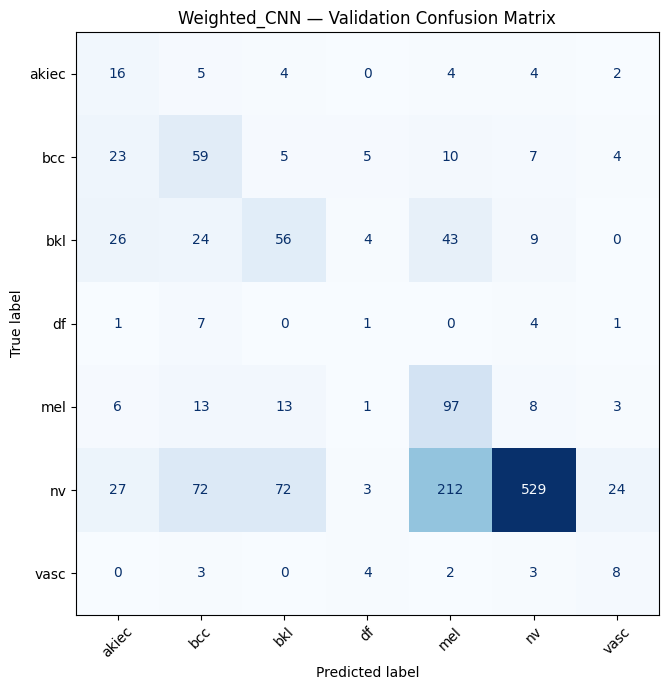


Unweighted_CNN
---------------------------------------------
Saved checkpoint epoch: 10
Accuracy: 0.6826
Balanced accuracy: 0.2599
Macro F1: 0.2768


,precision,recall,f1-score,support
akiec,0.2800,0.2000,0.2333,35.0000
bcc,0.4384,0.2832,0.3441,113.0000
bkl,0.4608,0.2901,0.3561,162.0000
df,0.0000,0.0000,0.0000,14.0000
mel,0.3864,0.1206,0.1838,141.0000
nv,0.7364,0.9255,0.8202,939.0000
vasc,0.0000,0.0000,0.0000,20.0000
accuracy,0.6826,0.6826,0.6826,0.6826
macro avg,0.3288,0.2599,0.2768,1424.0000
weighted avg,0.6180,0.6826,0.6326,1424.0000


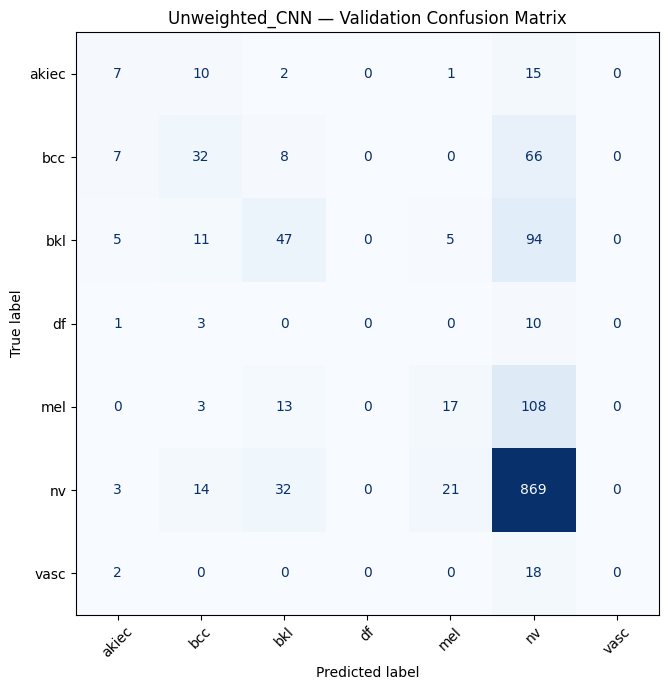


FINAL CNN ABLATION COMPARISON


,Model,Accuracy,Balanced Accuracy,Macro F1,Melanoma Recall,DF Recall,VASC Recall
0,Weighted_CNN,0.5379,0.4354,0.3432,0.6879,0.0714,0.4
1,Unweighted_CNN,0.6826,0.2599,0.2768,0.1206,0.0000,0.0



Results saved successfully!


In [8]:

import torch
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

experiment_dir = Path(
    "/content/drive/MyDrive/DMML_R3_Experiments/CNN_Ablation"
)

def evaluate_saved_cnn(name):

    path = experiment_dir / name / "best_model.pth"

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    model = SmallCNN(num_classes=7).to(device)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    true_labels = []
    predictions = []

    with torch.no_grad():
        for images, labels in val_loader:

            images = images.to(device)
            outputs = model(images)

            preds = outputs.argmax(dim=1).cpu().numpy()

            predictions.extend(preds)
            true_labels.extend(labels.numpy())

    accuracy = accuracy_score(true_labels, predictions)
    bal_accuracy = balanced_accuracy_score(
        true_labels, predictions
    )
    macro_f1 = f1_score(
        true_labels,
        predictions,
        average="macro",
        labels=list(range(7)),
        zero_division=0
    )

    print(f"\n{name}")
    print("-" * 45)
    print("Saved checkpoint epoch:", checkpoint["epoch"])
    print("Accuracy:", round(accuracy, 4))
    print("Balanced accuracy:", round(bal_accuracy, 4))
    print("Macro F1:", round(macro_f1, 4))

    report = classification_report(
        true_labels,
        predictions,
        labels=list(range(7)),
        target_names=classes,
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(report).transpose()

    display(report_df.round(4))

    save_folder = experiment_dir / name

    report_df.to_csv(
        save_folder / "classification_report.csv"
    )

    cm = confusion_matrix(
        true_labels,
        predictions,
        labels=list(range(7))
    )

    fig, ax = plt.subplots(figsize=(9, 7))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=classes
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    plt.title(f"{name} — Validation Confusion Matrix")
    plt.xticks(rotation=45)
    plt.tight_layout()

    fig.savefig(
        save_folder / "confusion_matrix.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    return {
        "Model": name,
        "Accuracy": accuracy,
        "Balanced Accuracy": bal_accuracy,
        "Macro F1": macro_f1,
        "Melanoma Recall": report["mel"]["recall"],
        "DF Recall": report["df"]["recall"],
        "VASC Recall": report["vasc"]["recall"]
    }


weighted_metrics = evaluate_saved_cnn("Weighted_CNN")
unweighted_metrics = evaluate_saved_cnn("Unweighted_CNN")

comparison_df = pd.DataFrame([
    weighted_metrics,
    unweighted_metrics
])

print("\nFINAL CNN ABLATION COMPARISON")
display(comparison_df.round(4))

comparison_df.to_csv(
    experiment_dir / "cnn_ablation_comparison.csv",
    index=False
)

print("\nResults saved successfully!")


## Part 9 — Re-evaluate the extended ResNet18 checkpoint (from notebook 03) on the validation set

In [9]:

import torch
from torchvision.models import resnet18
from pathlib import Path

# Improved model checkpoint
checkpoint_path = (
    project / "CNN Results" / "ResNet18" /
    "Improvement_Experiment" /
    "best_improved_resnet18.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

# Reconstruct the ResNet18 architecture
model = resnet18(weights=None)
model.fc = torch.nn.Linear(
    model.fc.in_features, 7
)

# Load trained weights
model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

model = model.to(device)
model.eval()

print("IMPROVED RESNET18 VERIFICATION")
print("-----------------------------")
print("Checkpoint loaded successfully!")
print("Saved epoch:", checkpoint["epoch"])
print("Saved Macro F1:", checkpoint["best_val_macro_f1"])
print("Classes:", checkpoint["classes"])
print("Device:", device)

print("\nPASS: Improved ResNet18 architecture verified!")


IMPROVED RESNET18 VERIFICATION
-----------------------------
Checkpoint loaded successfully!
Saved epoch: 17
Saved Macro F1: 0.6103008725768749
Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Device: cuda

PASS: Improved ResNet18 architecture verified!


In [10]:

import torch
import pandas as pd

from torchvision import transforms
from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

# ResNet18 validation preprocessing
resnet_val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Reuse our existing HAMDataset class
resnet_val_dataset = HAMDataset(
    val_df,
    resnet_val_transform
)

resnet_val_loader = DataLoader(
    resnet_val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

# Evaluate improved model
model.eval()

all_true = []
all_pred = []

with torch.no_grad():

    for images, labels in resnet_val_loader:

        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_true.extend(labels.numpy())
        all_pred.extend(predictions.cpu().numpy())

# Compute validation metrics
val_accuracy = accuracy_score(all_true, all_pred)

val_balanced_accuracy = balanced_accuracy_score(
    all_true, all_pred
)

val_macro_f1 = f1_score(
    all_true,
    all_pred,
    average="macro",
    labels=list(range(7)),
    zero_division=0
)

print("IMPROVED RESNET18 VALIDATION RESULTS")
print("------------------------------------")
print(f"Accuracy: {val_accuracy:.4f}")
print(f"Balanced Accuracy: {val_balanced_accuracy:.4f}")
print(f"Macro F1: {val_macro_f1:.4f}")

print("\nSaved checkpoint Macro F1:",
      round(checkpoint["best_val_macro_f1"], 4))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    all_true,
    all_pred,
    labels=list(range(7)),
    target_names=classes,
    zero_division=0
))


IMPROVED RESNET18 VALIDATION RESULTS
------------------------------------
Accuracy: 0.7282
Balanced Accuracy: 0.7034
Macro F1: 0.6103

Saved checkpoint Macro F1: 0.6103

CLASSIFICATION REPORT
              precision    recall  f1-score   support

       akiec       0.35      0.77      0.48        35
         bcc       0.76      0.68      0.72       113
         bkl       0.51      0.64      0.57       162
          df       0.53      0.64      0.58        14
         mel       0.38      0.68      0.49       141
          nv       0.95      0.76      0.84       939
        vasc       0.48      0.75      0.59        20

    accuracy                           0.73      1424
   macro avg       0.57      0.70      0.61      1424
weighted avg       0.81      0.73      0.75      1424



In [11]:

import pandas as pd
import json
from pathlib import Path

verification_dir = Path(
    "/content/drive/MyDrive/DMML_R3_Experiments/"
    "ResNet18_Verification"
)
verification_dir.mkdir(parents=True, exist_ok=True)

# Save prediction-level evidence
predictions_df = pd.DataFrame({
    "image_id": val_df["image_id"].to_numpy(),
    "true_label": [classes[int(i)] for i in all_true],
    "predicted_label": [classes[int(i)] for i in all_pred]
})

assert len(predictions_df) == 1424

predictions_df.to_csv(
    verification_dir / "validation_predictions.csv",
    index=False
)

# Save reproduced metrics
metrics = {
    "model": "Improved ResNet18",
    "checkpoint_epoch": int(checkpoint["epoch"]),
    "evaluation_split": "validation",
    "accuracy": float(val_accuracy),
    "balanced_accuracy": float(val_balanced_accuracy),
    "macro_f1": float(val_macro_f1),
    "validation_images": len(all_true)
}

with open(
    verification_dir / "verified_metrics.json", "w"
) as f:
    json.dump(metrics, f, indent=4)

print("RESNET18 VERIFICATION SAVED")
print("Predictions:", len(predictions_df))
print("Macro F1:", round(val_macro_f1, 4))

for file in sorted(verification_dir.iterdir()):
    print(file.name)


RESNET18 VERIFICATION SAVED
Predictions: 1424
Macro F1: 0.6103
validation_predictions.csv
verified_metrics.json


## Part 10 — Combined results tables and file inventory

In [12]:

import pandas as pd
from pathlib import Path

base = Path(
    "/content/drive/MyDrive/DMML_R3_Experiments"
)

# Classical ML validation results
classical = pd.read_csv(
    base / "Comparison" / "five_model_comparison.csv"
)

classical["Experiment"] = "Classical ML"
classical["Evaluation"] = "Validation"

# CNN ablation validation results
cnn = pd.read_csv(
    base / "CNN_Ablation" / "cnn_ablation_comparison.csv"
)

cnn["Experiment"] = "CNN Ablation"
cnn["Evaluation"] = "Validation"

# Verified improved ResNet18
resnet = pd.DataFrame([{
    "Model": "Improved ResNet18",
    "Accuracy": val_accuracy,
    "Balanced Accuracy": val_balanced_accuracy,
    "Macro F1": val_macro_f1,
    "Experiment": "Transfer Learning",
    "Evaluation": "Validation"
}])

# Combine shared metrics
columns = [
    "Model", "Accuracy", "Balanced Accuracy",
    "Macro F1", "Experiment", "Evaluation"
]

master_results = pd.concat([
    classical[columns],
    cnn[columns],
    resnet[columns]
], ignore_index=True)

master_results = master_results.sort_values(
    "Macro F1",
    ascending=False
).reset_index(drop=True)

# Save master comparison
output = base / "master_experiment_results.csv"

master_results.to_csv(output, index=False)

print("MASTER EXPERIMENT RESULTS")
display(master_results.round(4))

print("\nSaved to:", output)


MASTER EXPERIMENT RESULTS


,Model,Accuracy,Balanced Accuracy,Macro F1,Experiment,Evaluation
0,Improved ResNet18,0.7282,0.7034,0.6103,Transfer Learning,Validation
1,Weighted_CNN,0.5379,0.4354,0.3432,CNN Ablation,Validation
2,Unweighted_CNN,0.6826,0.2599,0.2768,CNN Ablation,Validation
3,kNN,0.6629,0.2311,0.2352,Classical ML,Validation
4,Random Forest,0.4171,0.3079,0.2281,Classical ML,Validation
5,Decision Tree (Tuned),0.6728,0.2155,0.2191,Classical ML,Validation
6,Naive Bayes (Tuned),0.6966,0.2119,0.2115,Classical ML,Validation
7,Logistic Regression,0.4052,0.3398,0.2021,Classical ML,Validation



Saved to: /content/drive/MyDrive/DMML_R3_Experiments/master_experiment_results.csv


In [13]:

import pandas as pd
from pathlib import Path

base = Path(
    "/content/drive/MyDrive/DMML_R3_Experiments"
)

# Load the existing eight-model comparison
master_results = pd.read_csv(
    base / "master_experiment_results.csv"
)

# Previously completed neural-network experiments
missing_models = pd.DataFrame([
    {
        "Model": "Original ANN",
        "Accuracy": 0.6959269663,
        "Balanced Accuracy": 0.2163950930,
        "Macro F1": 0.2138518647,
        "Experiment": "Metadata ANN",
        "Evaluation": "Validation"
    },
    {
        "Model": "Balanced ANN",
        "Accuracy": 0.4058988764,
        "Balanced Accuracy": 0.2925602269,
        "Macro F1": 0.2273029409,
        "Experiment": "Metadata ANN",
        "Evaluation": "Validation"
    },
    {
        "Model": "Original Small CNN",
        "Accuracy": 0.5358,
        "Balanced Accuracy": float("nan"),
        "Macro F1": 0.3585,
        "Experiment": "CNN",
        "Evaluation": "Validation"
    },
    {
        "Model": "Frozen ResNet18",
        "Accuracy": 0.5856741573,
        "Balanced Accuracy": float("nan"),
        "Macro F1": 0.4353670605,
        "Experiment": "Transfer Learning",
        "Evaluation": "Validation"
    },
    {
        "Model": "First Fine-tuned ResNet18",
        "Accuracy": 0.6235955056,
        "Balanced Accuracy": 0.6680846527,
        "Macro F1": 0.4857085660,
        "Experiment": "Transfer Learning",
        "Evaluation": "Validation"
    }
])

# Combine without duplicating existing experiments
master_results = master_results[
    ~master_results["Model"].isin(missing_models["Model"])
]

master_results = pd.concat(
    [master_results, missing_models],
    ignore_index=True
)

master_results = master_results.sort_values(
    "Macro F1",
    ascending=False
).reset_index(drop=True)

# Preserve previous file and save a new complete version
output = base / "master_experiment_results_complete.csv"

master_results.to_csv(output, index=False)

print("COMPLETE DMML VALIDATION RESULTS")
display(master_results.round(4))

print("\nTotal experiments:", len(master_results))
print("Saved to:", output)


COMPLETE DMML VALIDATION RESULTS


,Model,Accuracy,Balanced Accuracy,Macro F1,Experiment,Evaluation
0,Improved ResNet18,0.7282,0.7034,0.6103,Transfer Learning,Validation
1,First Fine-tuned ResNet18,0.6236,0.6681,0.4857,Transfer Learning,Validation
2,Frozen ResNet18,0.5857,NaN,0.4354,Transfer Learning,Validation
3,Original Small CNN,0.5358,NaN,0.3585,CNN,Validation
4,Weighted_CNN,0.5379,0.4354,0.3432,CNN Ablation,Validation
5,Unweighted_CNN,0.6826,0.2599,0.2768,CNN Ablation,Validation
6,kNN,0.6629,0.2311,0.2352,Classical ML,Validation
7,Random Forest,0.4171,0.3079,0.2281,Classical ML,Validation
8,Balanced ANN,0.4059,0.2926,0.2273,Metadata ANN,Validation
9,Decision Tree (Tuned),0.6728,0.2155,0.2191,Classical ML,Validation



Total experiments: 13
Saved to: /content/drive/MyDrive/DMML_R3_Experiments/master_experiment_results_complete.csv


In [14]:

import pandas as pd
from pathlib import Path

base = Path(
    "/content/drive/MyDrive/DMML_R3_Experiments"
)

practical_comparison = pd.DataFrame([
    {
        "Model": "Decision Tree",
        "Practical Strength": "Interpretable rules using clinical metadata",
        "Practical Limitation": (
            "Poor minority-class recognition; "
            "risk of overfitting"
        ),
        "Validation Macro F1": 0.2191,
        "Suitable for Clinical Deployment": False
    },
    {
        "Model": "kNN",
        "Practical Strength": (
            "Similarity-based classification using "
            "previously labelled examples"
        ),
        "Practical Limitation": (
            "Sensitive to feature scaling, "
            "neighbour choice and imbalance"
        ),
        "Validation Macro F1": 0.2352,
        "Suitable for Clinical Deployment": False
    },
    {
        "Model": "Naive Bayes",
        "Practical Strength": (
            "Simple and computationally inexpensive "
            "probabilistic baseline"
        ),
        "Practical Limitation": (
            "Strong distributional assumptions and "
            "poor minority-class recognition"
        ),
        "Validation Macro F1": 0.2115,
        "Suitable for Clinical Deployment": False
    }
])

output = base / "r3_practical_model_evaluation.csv"

practical_comparison.to_csv(
    output,
    index=False
)

print("R3 PRACTICAL EVALUATION")
display(practical_comparison)

print("\nSaved to:", output)


R3 PRACTICAL EVALUATION


,Model,Practical Strength,Practical Limitation,Validation Macro F1,Suitable for Clinical Deployment
0,Decision Tree,Interpretable rules using clinical metadata,Poor minority-class recognition; risk of overf...,0.2191,False
1,kNN,Similarity-based classification using previous...,"Sensitive to feature scaling, neighbour choice...",0.2352,False
2,Naive Bayes,Simple and computationally inexpensive probabi...,Strong distributional assumptions and poor min...,0.2115,False



Saved to: /content/drive/MyDrive/DMML_R3_Experiments/r3_practical_model_evaluation.csv


In [15]:

from pathlib import Path
import pandas as pd

folders = {
    "Original DMML Project":
        Path("/content/drive/MyDrive/DMML Project"),

    "New Experiments":
        Path("/content/drive/MyDrive/DMML_R3_Experiments")
}

inventory = []

for project_name, folder in folders.items():

    if not folder.exists():
        print("FOLDER NOT FOUND:", folder)
        continue

    for file in folder.rglob("*"):

        if file.is_file():

            inventory.append({
                "Project": project_name,
                "File": file.name,
                "Relative Path": str(file.relative_to(folder)),
                "Extension": file.suffix.lower(),
                "Size MB": round(
                    file.stat().st_size / (1024 ** 2), 3
                )
            })

inventory_df = pd.DataFrame(inventory)

print("DMML PROJECT FILE INVENTORY")
print("---------------------------")

print("Total files:", len(inventory_df))

print("\nFiles by project:")
display(
    inventory_df.groupby("Project")
    .size()
    .reset_index(name="File Count")
)

print("\nFiles by extension:")
display(
    inventory_df.groupby("Extension")
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

# Save the inventory outside the original project
output = Path(
    "/content/drive/MyDrive/DMML_R3_Experiments/"
    "project_file_inventory.csv"
)

inventory_df.to_csv(output, index=False)

print("\nInventory saved to:", output)


DMML PROJECT FILE INVENTORY
---------------------------
Total files: 96

Files by project:


,Project,File Count
0,New Experiments,33
1,Original DMML Project,63



Files by extension:


,Extension,Count
5,.png,41
0,.csv,36
6,.pth,8
3,.json,4
2,.joblib,2
1,.ipynb,2
7,.zip,2
4,.pdf,1



Inventory saved to: /content/drive/MyDrive/DMML_R3_Experiments/project_file_inventory.csv
